<a href="https://colab.research.google.com/github/Kommmi/Chain_GQS/blob/main/gqs_interaction_sweep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GQS of two electrons on L sites: interaction sweep

Thin experiment notebook: all functions live in `chain_gqs`. Change parameters here only.

In [1]:
!rm -rf chain_gqs
# Clean slate
#!pip uninstall -y gqs
!git clone https://github.com/Kommmi/Chain_GQS.git

# Move into the repo
%cd Chain_GQS

# Install dependencies
#!pip install -r requirements.txt

# Install the package in editable mode
!pip install -e .

from IPython.display import clear_output
clear_output()

print("Module ready to go :)")

Module ready to go :)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from chain_gqs import ChainModel, townsend2021, coulomb, product_state, gqs_history, projected_ensemble, check_ensemble
from chain_gqs.plotting import plot_gqs_history, plot_sector_weights

## Parameters

In [3]:
L, N = 5, 2
subsystem = (0, 1)
occupied = (0, 2)
dt, nsteps = 0.02, 300
method = 'trotter'   # 'exact' removes Trotter error

# Model: Townsend et al. parameters, swept in lam_ee/t.
model = townsend2021(L=L, N=N, lam_ee=1.0, t=1.0)
sweep = dict(lam_ee=[0.5, 2.0, 10.0])

# Original notebook model instead:
# model = coulomb(L=L, N=N, J=1.0, V=1.0)
# sweep = dict(J=[0.5, 1.0, 1.5])

## Single snapshot

In [10]:
print(model.label)
times, Q = gqs_history(model, product_state(L, occupied), nsteps, dt, subsystem, method)
display(Q[-1].sector_table(style='pe'))      # Table 1: charge distribution on the dimer
display(Q[-1].ensemble_table(style='pe'))    # Table 2: one row per environment configuration

townsend2021(L=5, N=2, lam_ee=1, t=1, f_ex=0.2, zeta_ee=0.5, zeta_nuc=0.5, include_self=True)


,n_E,P(n_S),subsystem states,environment configs
n_S,,,,
2,0,0.277,|11⟩,1
1,1,0.571,α|01⟩ + β|10⟩ (Bloch sphere),3
0,2,0.151,|00⟩,3


,n_E,n_S,λ,p(a | n_S),|χ⟩,θ/π,φ/π,P(electron on site 0)
environment |n₂n₃n₄⟩,,,,,,,,
|000⟩,0,2,0.277,1.000,|11⟩,—,—,—
|001⟩,1,1,0.240,0.420,0.257|01⟩ + 0.966·e^(0.75πi)|10⟩,0.834,0.751,0.934
|010⟩,1,1,0.178,0.312,0.272|01⟩ + 0.962·e^(0.50πi)|10⟩,0.825,0.501,0.926
|100⟩,1,1,0.153,0.268,0.553|01⟩ + 0.833·e^(1.57πi)|10⟩,0.627,1.572,0.694
|011⟩,2,0,0.012,0.077,|00⟩,—,—,—
|101⟩,2,0,0.073,0.484,|00⟩,—,—,—
|110⟩,2,0,0.066,0.439,|00⟩,—,—,—


In [11]:
display(Q[-1].sector_table(style='cm'))      # Table 1: charge distribution on the dimer
display(Q[-1].ensemble_table(style='cm'))    # Table 2: one row per environment configuration

,charge on rest of chain,probability,dimer state,configurations
charge on dimer,,,,
2,0,0.277,doubly occupied |11⟩,1
1,1,0.571,one electron shared across the bond,3
0,2,0.151,empty dimer |00⟩,3


,probability,imbalance ⟨n₀−n₁⟩,bond order ⟨c₀†c₁+h.c.⟩,bond current j₀→₁/J
rest of chain |n₂n₃n₄⟩,,,,
|001⟩,0.240,0.867,-0.353,-0.351
|010⟩,0.178,0.852,-0.002,-0.523
|100⟩,0.153,0.388,0.206,0.899


## Sweep over J/V

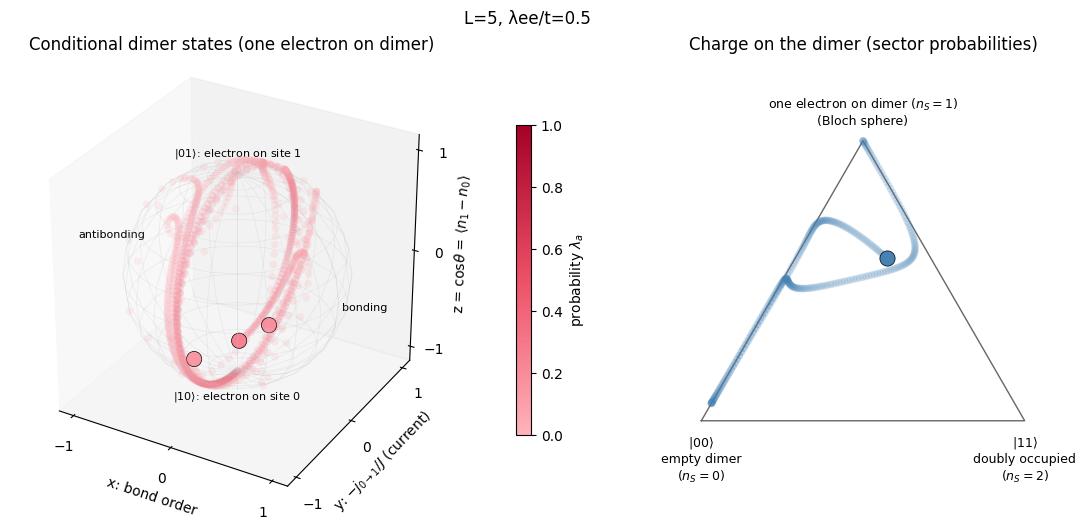

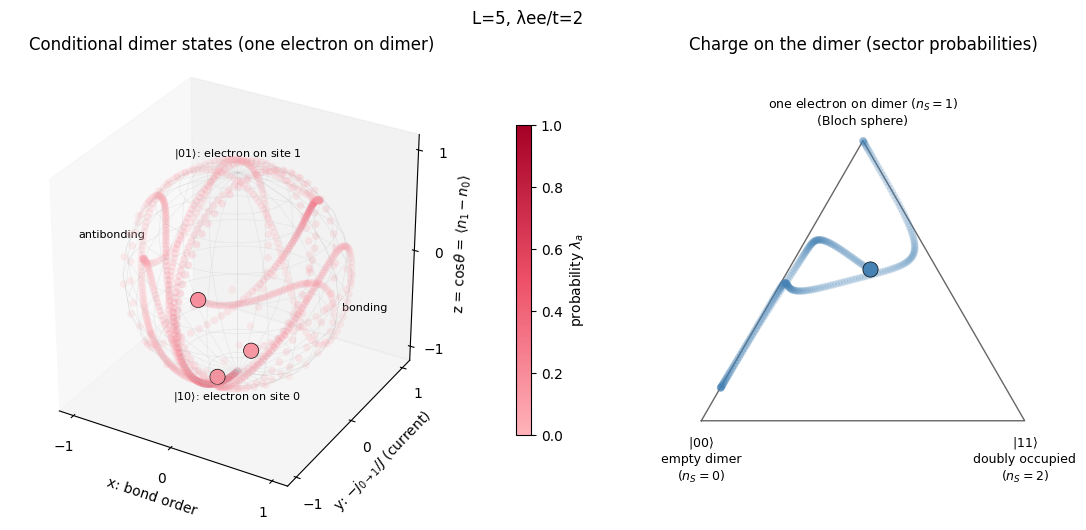

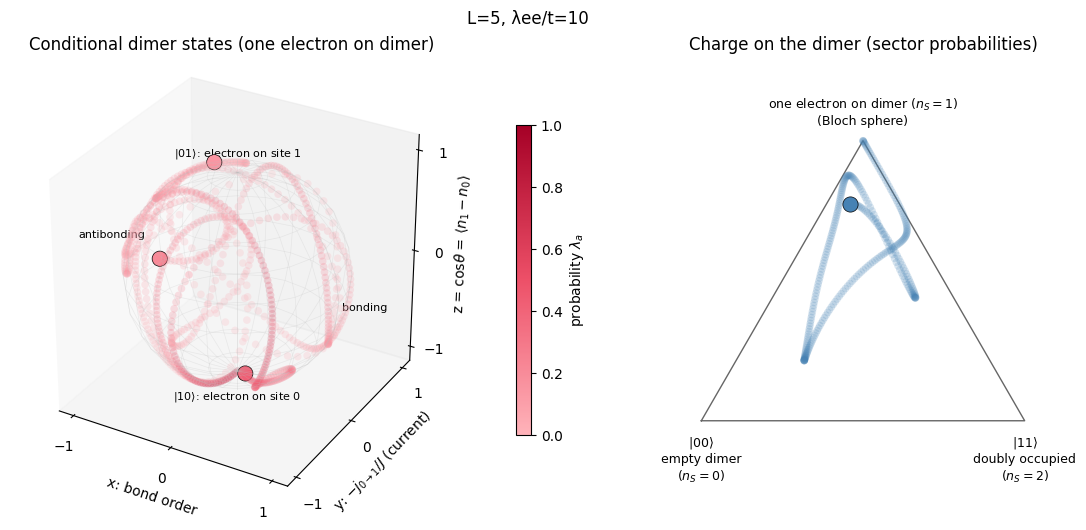

In [12]:
(key, values), = sweep.items()
results = {}
for v in values:
    m = model.with_(**{key: v})
    results[v] = gqs_history(m, product_state(L, occupied), nsteps, dt, subsystem, method)
    fig, _ = plot_gqs_history(results[v][1], bloch_view='sphere', title=f"L={L}, λee/t={v:g}")
    plt.show()

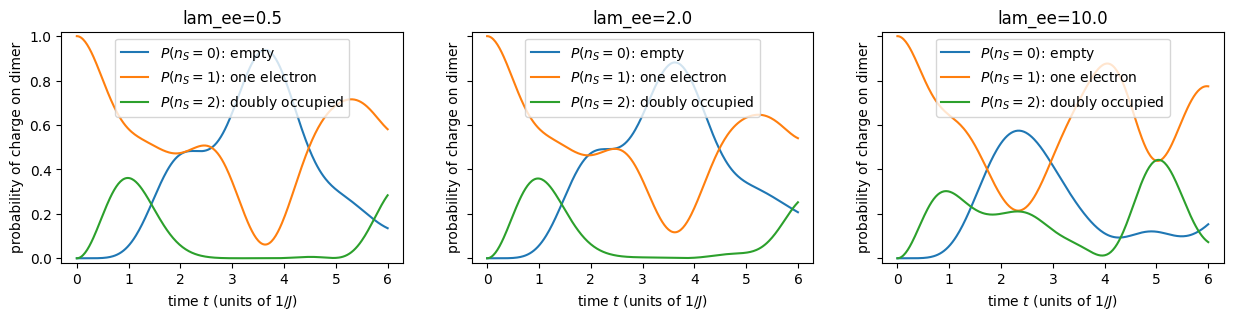

In [13]:
fig, axes = plt.subplots(1, len(values), figsize=(15, 3), sharey=True)
for ax, v in zip(axes, values):
    plot_sector_weights(*results[v], ax=ax)
    ax.set_title(f'{key}={v}')
plt.show()

## Measurement-based reconstruction (needs Qiskit)

In [ ]:
from chain_gqs.quantum import build_circuit, gqs_measurement_circuits, sample_counts
from chain_gqs import reconstruct_from_counts, require_pure_reconstruction

sample_steps = np.arange(0, 201, 5)
Q_measured = []
for i, n in enumerate(sample_steps):
    circ = build_circuit(model, int(n), dt, occupied)
    counts = sample_counts(gqs_measurement_circuits(circ, subsystem), shots=10_000, seed=100 + i)
    Q_measured.append(require_pure_reconstruction(
        reconstruct_from_counts(counts, L, subsystem, N, assume_pure=True)))
fig, _ = plot_gqs_history(Q_measured, bloch_view='angles')
plt.show()